In [2]:
import numpy as np
import os
import tensorflow as tf

from models import ConvNet, SoftBinaryDecisionTree
# from models.unlearning import UnlearningSDT
from models.utils import brand_new_tfsession, draw_tree
from tensorflow.keras.callbacks import EarlyStopping, Callback

# 새 세션 시작
sess = brand_new_tfsession()

c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\tensorflow\python\framework\dtypes.py:526: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\tensorflow\python\framework\dtypes.py:527: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\tensorflow\python\framework\dtypes.py:528: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages

In [3]:
# ✅ FashionMNIST 데이터 로드
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# 채널 차원 추가 (MNIST처럼 흑백이므로 1채널)
x_train, x_test = x_train[..., np.newaxis], x_test[..., np.newaxis]

# 마지막 10000개를 검증용으로 분리
x_valid, y_valid = x_train[-10000:], y_train[-10000:]
x_train, y_train = x_train[:-10000], y_train[:-10000]

print(x_train.shape, y_train.shape, x_valid.shape, y_valid.shape, x_test.shape, y_test.shape)


(50000, 28, 28, 1) (50000,) (10000, 28, 28, 1) (10000,) (10000, 28, 28, 1) (10000,)


In [4]:
# 이미지 크기 및 클래스 수 추출
img_rows, img_cols, img_chans = x_train.shape[1:]
n_classes = np.unique(y_train).shape[0]
print(img_rows, img_cols, img_chans, n_classes)

28 28 1 10


In [5]:
# 원-핫 인코딩
y_train = tf.keras.utils.to_categorical(y_train, n_classes)
y_valid = tf.keras.utils.to_categorical(y_valid, n_classes)
y_test = tf.keras.utils.to_categorical(y_test, n_classes)
print(y_train.shape, y_valid.shape, y_test.shape)

(50000, 10) (10000, 10) (10000, 10)


In [6]:
# 정규화
x_train = (x_train / 255.0).astype(np.float32)
x_valid = (x_valid / 255.0).astype(np.float32)
x_test = (x_test / 255.0).astype(np.float32)


In [7]:
# ConvNet 학습
Fashion_nn = ConvNet(img_rows, img_cols, img_chans, n_classes,
             model_path='assets/fashionmnist_teacher/fashionmnist-model.hdf5')  # <- 별도 저장 권장
Fashion_nn.maybe_train(data_train=(x_train, y_train),
               data_valid=(x_valid, y_valid),
               batch_size=16, epochs=20)  

Instructions for updating:
Colocations handled automatically by placer.
🔁 Loading trained model from assets/fashionmnist_teacher/fashionmnist-model.hdf5.
Instructions for updating:
Please use `rate` instead of `keep_prob`. Rate should be set to `rate = 1 - keep_prob`.


In [7]:
Fashion_nn.evaluate(x_valid, y_valid)
Fashion_nn.evaluate(x_test, y_test)

Evaluation Results:
 - Loss:      0.2115
 - Accuracy:  93.61%
 - Precision: 93.62%
 - Recall:    93.63%
 - F1-Score:  93.60%
Evaluation Results:
 - Loss:      0.2284
 - Accuracy:  93.34%
 - Precision: 93.33%
 - Recall:    93.34%
 - F1-Score:  93.30%


In [8]:
# Soft label 생성
y_train_soft = Fashion_nn.predict(x_train)

50000/50000 [==============================] - 13s 261us/sample


In [9]:
# Flatten for SDT
x_train_flat = x_train.reshape((x_train.shape[0], -1))
x_valid_flat = x_valid.reshape((x_valid.shape[0], -1))
x_test_flat = x_test.reshape((x_test.shape[0], -1))

print(x_train_flat.shape, x_valid_flat.shape, x_test_flat.shape)

(50000, 784) (10000, 784) (10000, 784)


In [ ]:
import optuna
from tensorflow.keras.callbacks import EarlyStopping
import glob

n_features = img_rows * img_cols * img_chans

def objective(trial):
    # 1. 튜닝할 하이퍼파라미터 설정
    tree_depth = trial.suggest_int("tree_depth", 3, 5)
    penalty_strength = trial.suggest_loguniform("penalty_strength", 1e-2, 1e+1)
    penalty_decay = trial.suggest_uniform("penalty_decay", 0.01, 0.5)
    ema_win_size = trial.suggest_int("ema_win_size", 500, 1000, step = 100)
    inv_temp = trial.suggest_uniform("inv_temp", 0.01, 0.1)
    learning_rate = trial.suggest_float("learning_rate", 5e-04, 1e-02, log = True)
    batch_size = trial.suggest_categorical("batch_size", [4, 8, 16])
    
    # 고유한 체크포인트 경로 생성 (Trial 번호 기반)
    checkpoint_dir = f"assets/optuna_trial/trial_{trial.number}/"
    checkpoint_path = os.path.join(checkpoint_dir, "tree-model")

    # 💡 기존 체크포인트가 있다면 삭제
    if os.path.isdir(checkpoint_dir):
        old_ckpts = glob.glob(os.path.join(checkpoint_dir, "tree-model*"))
        for file in old_ckpts:
            os.remove(file)
    else:
        os.makedirs(checkpoint_dir, exist_ok=True)


    # 2. 트리 모델 생성
    sess = brand_new_tfsession()  # 세션 초기화
    fashion_tree = SoftBinaryDecisionTree(
        tree_depth, n_features, n_classes,
        penalty_strength=penalty_strength,
        penalty_decay=penalty_decay,
        inv_temp=inv_temp,
        ema_win_size=ema_win_size,
        learning_rate=learning_rate
    )
    fashion_tree.build_model()

    # 3. 학습
    es = EarlyStopping(monitor='val_acc', patience=5, verbose=0)
    fashion_tree.initialize_variables(sess, x_train_flat, batch_size)

    fashion_tree.maybe_train(
        sess = sess,
        data_train = (x_train_flat, y_train_soft),
        data_valid=(x_valid_flat, y_valid),
        batch_size=batch_size,
        epochs=20,  # 빠른 튜닝용 짧은 epoch (본 학습 때는 늘리면 됨)
        callbacks=[es],
        model_path=checkpoint_path
    )

    # 4. 평가 지표 반환 (validation accuracy)
    score = fashion_tree.fashion_evaluate(x_valid_flat, y_valid, batch_size=batch_size)
    return score[1]  # val_acc

# 5. Optuna 튜닝 시작
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20)  # 20번 실험 (조절 가능)

# 6. 최적 파라미터 확인
print("🎯 Best trial:")
print(study.best_trial)


In [ ]:
best_params = study.best_trial.params

In [10]:
# 0.8185999989509583
n_features = img_rows * img_cols * img_chans

sess = brand_new_tfsession()

fashion_tree = SoftBinaryDecisionTree(
    max_depth=4,
    n_features=n_features,
    n_classes=n_classes,
    penalty_strength=9.46994368188799,
    penalty_decay=0.12184151808100285,
    ema_win_size=900,
    inv_temp=0.08691355897145693,
    learning_rate=0.003193825703387617
)
fashion_tree.build_model()

Built tree has 16 leaves out of 31 nodes


In [11]:
# import glob
# import os
# for f in glob.glob('assets/fashion_tree/tree-model*'):
#     os.remove(f)

import time
start_time = time.time()
print("🟢 학습 시작:", time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(start_time)))

fashion_tree.maybe_train(
    sess=sess,
    data_train=(x_train_flat, y_train_soft),
    data_valid=(x_valid_flat, y_valid),
    batch_size=4,
    epochs=40,
    callbacks=[EarlyStopping(monitor='val_acc', patience=10)],
    distill=True,
    model_path = "assets/fashionmnist_student/fashion_tree-distill-tree/tree-model"
)

# 4. 종료 시간 기록
end_time = time.time()
print("🔴 학습 종료:", time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(end_time)))

# 5. 총 소요 시간
elapsed = end_time - start_time
print(f"⏱️ 총 학습 시간: {elapsed:.2f}초 ({elapsed / 60:.2f}분)")

🟢 학습 시작: 2025-06-11 11:27:45
Loading trained model from assets/fashionmnist_student/fashion_tree-distill-tree/tree-model.
Instructions for updating:
Use standard file APIs to check for files with this prefix.
INFO:tensorflow:Restoring parameters from assets/fashionmnist_student/fashion_tree-distill-tree/tree-model
🔴 학습 종료: 2025-06-11 11:27:45
⏱️ 총 학습 시간: 0.06초 (0.00분)


In [14]:
fashion_tree.evaluate(x=x_valid_flat, y=y_valid, batch_size=4)
fashion_tree.evaluate(x=x_test_flat, y=y_test, batch_size=4)

Evaluation Results:
 - Accuracy:  85.05%
 - Precision: 85.09%
 - Recall:    85.05%
 - F1-Score:  84.91%
Evaluation Results:
 - Accuracy:  84.41%
 - Precision: 84.46%
 - Recall:    84.41%
 - F1-Score:  84.21%


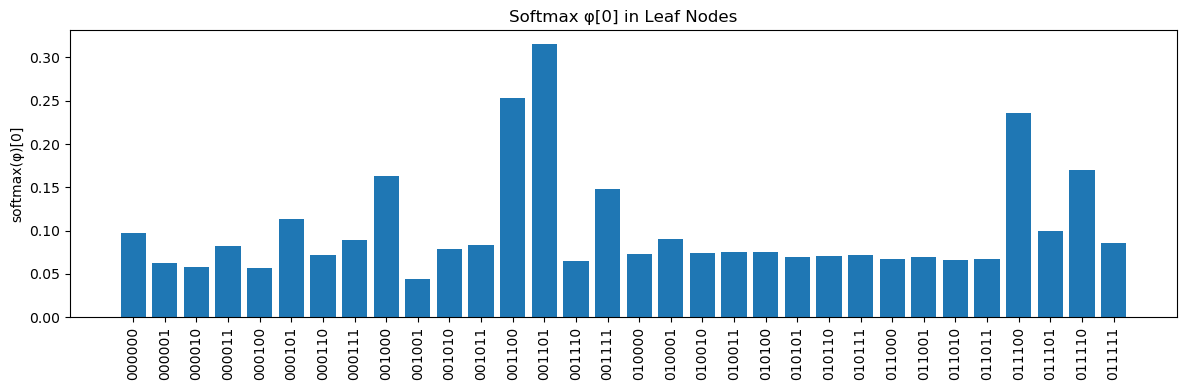

In [13]:
import matplotlib.pyplot as plt

def plot_leaf_node_phi_softmax(tree, sess, target_class=3):
    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = []
    node_ids = []

    for leaf in leaves:
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)
        phi_values.append(soft_phi[target_class])
        node_ids.append(leaf.id)

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(phi_values)), phi_values, tick_label=node_ids)
    plt.xticks(rotation=90)
    plt.ylabel(f"softmax(φ)[{target_class}]")
    plt.title(f"Softmax φ[{target_class}] in Leaf Nodes")
    plt.tight_layout()
    plt.show()


plot_leaf_node_phi_softmax(tree=fashion_tree, sess=sess, target_class=0)


In [15]:
# labels = ["T-shirt/top", index 0
        # "Trouser",       index 1
        # "Pullover",      index 2 
        # "Dress",         index 3 
        # "Coat",          index 4
        # "Sandal",        index 5
        # "Shirt",         index 6 
        # "Sneaker",       index 7 
        # "Bag",           index 8 
        # "Ankle boot"]    index 9

label = 0

# get (reproducibly) pseudo-random example of chosen digit
np.random.seed(0)
sample_index = np.random.choice(np.where(np.argmax(y_test, axis=1)==label)[0])
input_img = x_test[sample_index]

draw_tree(sess, fashion_tree, img_rows, img_cols, img_chans, input_img=input_img, savepath = 'tree_visualization_before unlearning(FashionMNIST).pdf')

In [12]:
# 리프 노드들 중에서 target classs를 가장 강하게 예측하는 리프를 찾음
# 각 타겟 리프에 대해 유사한 (하지만 target_class를 예측하지 않는) 리프 top_k개를 찾음 (코사인 유사도 기반)
# 타겟 클래스의 φ 확률 중 일부 (α 비율)를 유사 리프들로 soft하게 분산시키고, 나머지는 자신에게 남김
# 리프가 도달하는 경로에 있는 inner node들의 weight를 soft pruning 방식으로 약화
# 변경된 φ와 weight 저장

# target_class를 예측하는 리프를 찾고 → 그 φ 확률을 유사한 다른 리프로 soft하게 분산

# 해당 리프의 경로를 pruning하여 영향력을 감소시키고 → 여전히 남은 φ 값은 soft하게 suppress (모델 내부에서 특정 클래스 (target class)에 대한 예측을 의도적으로 낮추는 것)

# 결과적으로, 모델이 target_class를 예측하지 못하게 유도하면서도 전체 구조는 유지

def unlearn_target_class(tree, sess, target_class=3, top_k=3, alpha=0.3, pruning_rate=0.7, save_path=None):
    import numpy as np
    from sklearn.metrics.pairwise import cosine_similarity

    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = sess.run([leaf.phi for leaf in leaves])

    target_leaves = []
    for leaf, phi in zip(leaves, phi_values):
        if np.argmax(phi) == target_class:
            target_leaves.append(leaf)

    similar_map = {}
    for t_leaf in target_leaves:
        t_phi = sess.run(t_leaf.phi).reshape(1, -1)
        sims = []
        for other_leaf in leaves:
            if other_leaf == t_leaf:
                continue
            o_phi = sess.run(other_leaf.phi).reshape(1, -1)
            # 🔒 분산 대상 리프의 φ[0]이 이미 dominant한 경우 제외
            if np.argmax(o_phi) == target_class or o_phi[0, target_class] > 0.2:
                continue
            sim = cosine_similarity(t_phi, o_phi)[0, 0]
            sims.append((other_leaf, sim))
        similar_map[t_leaf] = sorted(sims, key=lambda x: -x[1])[:top_k]

    for t_leaf in target_leaves:
        t_phi_val = sess.run(t_leaf.phi)
        phi_tc = t_phi_val[0, target_class]
        residual_phi = np.copy(t_phi_val)

        redistributed_value = phi_tc * alpha
        residual_phi[0, target_class] = phi_tc * (1 - alpha)

        total_sim = sum([s for _, s in similar_map[t_leaf]]) + 1e-8
        for other_leaf, sim in similar_map[t_leaf]:
            ratio = sim / total_sim
            addition = redistributed_value * ratio

            other_phi_val = sess.run(other_leaf.phi)
            updated_phi = np.copy(other_phi_val)
            updated_phi[0, target_class] += addition

            # ⚠️ 추가 조건: 업데이트 후에도 target_class가 max가 되면 적용 안 함
            if np.argmax(updated_phi) == target_class:
                continue

            updated_phi /= np.sum(updated_phi) + 1e-8
            phi_var = [v for v in tf.global_variables()
                       if v.name.startswith('phi_' + other_leaf.id)][0]
            sess.run(tf.assign(phi_var, updated_phi.astype(np.float32)))

        residual_phi /= np.sum(residual_phi) + 1e-8
        phi_var = [v for v in tf.global_variables()
                   if v.name.startswith('phi_' + t_leaf.id)][0]
        sess.run(tf.assign(phi_var, residual_phi.astype(np.float32)))

        def find_path_to_leaf(root, target):
            path = []
            def dfs(node, current_path):
                if node == target:
                    path.extend(current_path)
                    return True
                if node.isLeaf:
                    return False
                return dfs(node.leftChild, current_path + [node]) or dfs(node.rightChild, current_path + [node])
            dfs(tree.root, [])
            return path

        importance = float(t_phi_val[0, target_class])
        pruning_scale = 1.0 - importance * pruning_rate

        path_nodes = find_path_to_leaf(tree.root, t_leaf)
        for node in path_nodes:
            dense_vars = [v for v in tf.global_variables()
                          if v.name.startswith('dense_' + node.id)]
            for var in dense_vars:
                current_val = sess.run(var)
                weakened_val = current_val * pruning_scale
                sess.run(tf.assign(var, weakened_val))

    # 🔧 전체 리프 노드 중 φ[target_class]가 여전히 높은 경우 soft suppression 추가
    for leaf, phi_val in zip(leaves, phi_values):
        if leaf in target_leaves:
            continue
        if phi_val[0, target_class] > 0.01:
            adjusted_phi = np.copy(phi_val)
            adjusted_phi[0, target_class] *= (1 - alpha)
            adjusted_phi /= np.sum(adjusted_phi) + 1e-8
            phi_var = [v for v in tf.global_variables() if v.name.startswith('phi_' + leaf.id)][0]
            sess.run(tf.assign(phi_var, adjusted_phi.astype(np.float32)))

    print("✅ Soft redistribution unlearning applied to class", target_class)

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        tree.save_variables(sess, save_path)
        print(f"📁 Unlearned model saved to: {save_path}")



In [13]:
x_train_flat = x_train.reshape(x_train.shape[0], -1)
# 테스트 데이터도 동일하게 처리
x_test_flat = x_test.reshape(x_test.shape[0], -1)

target_class = 0

# 예시 경로 지정
save_path = "result/fashionmnist/unlearned_fashion_mnist"

# 언러닝 및 저장 실행
unlearn_target_class(fashion_tree, sess, target_class=0, top_k=2, alpha=0.5, pruning_rate=0.6, save_path=save_path)
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
# 언러닝 후 모델 평가
# 테스트 데이터셋으로 평가
feed_dict = {fashion_tree.input_layer: x_test_flat}
predictions = sess.run(fashion_tree.output_layer, feed_dict=feed_dict)
pred_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(y_test, axis=1)

accuracy = np.mean(pred_classes == true_classes)
print(f"\nTest accuracy after unlearning: {accuracy:.4f}")

# 전체 성능 지표
print("\n=== Overall Performance ===")
print(f"Precision (macro): {precision_score(true_classes, pred_classes, average='macro'):.4f}")
print(f"Recall    (macro): {recall_score(true_classes, pred_classes, average='macro'):.4f}")
print(f"F1-score  (macro): {f1_score(true_classes, pred_classes, average='macro'):.4f}")
print("\n=== Full Classification Report ===")

# 🎯 타겟 클래스에 대한 성능
target_class = 0
target_mask = np.argmax(y_test, axis=1) == target_class
if np.sum(target_mask) > 0:
    print("\n=== Target Class Performance ===")
    target_acc = np.mean(pred_classes[target_mask] == true_classes[target_mask])
    print(f"Target class accuracy: {target_acc:.4f}")
    print(f"Target class precision: {precision_score(true_classes[target_mask], pred_classes[target_mask], average='micro', zero_division=0):.4f}")
    print(f"Target class recall:    {recall_score(true_classes[target_mask], pred_classes[target_mask], average='macro', zero_division=0):.4f}")
    print(f"Target class F1-score:  {f1_score(true_classes[target_mask], pred_classes[target_mask], average='macro', zero_division=0):.4f}")

# ✅ 비타겟 클래스 성능
non_target_mask = np.argmax(y_test, axis=1) != target_class
if np.sum(non_target_mask) > 0:
    print("\n=== Non-Target Class Performance ===")
    non_target_acc = np.mean(pred_classes[non_target_mask] == true_classes[non_target_mask])
    print(f"Non-target class accuracy: {non_target_acc:.4f}")
    print(f"Non-target precision: {precision_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")
    print(f"Non-target recall:    {recall_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")
    print(f"Non-target F1-score:  {f1_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")


✅ Soft redistribution unlearning applied to class 0
📁 Unlearned model saved to: result/fashionmnist/unlearned_fashion_mnist

Test accuracy after unlearning: 0.7537

=== Overall Performance ===
Precision (macro): 0.7225
Recall    (macro): 0.7537
F1-score  (macro): 0.7238

=== Full Classification Report ===

=== Target Class Performance ===
Target class accuracy: 0.0000
Target class precision: 0.0000
Target class recall:    0.0000
Target class F1-score:  0.0000

=== Non-Target Class Performance ===
Non-target class accuracy: 0.8374
Non-target precision: 0.8451
Non-target recall:    0.8374
Non-target F1-score:  0.8336


c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\sklearn\metrics\_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
# 언러닝 후 정확도 평가
print("🔍 [After Unlearning] Evaluation on test set")
fashion_tree.evaluate(x_test_flat, y_test, batch_size=4)

# 동일한 digit = 3 입력 이미지로 시각화
digit = 0
target_indices = np.where(np.argmax(y_test, axis=1) == digit)[0]

# 언러닝 후 트리 시각화 저장
for i in range(5):
    x_sample = x_test[target_indices[i]]  # (28, 28)
    print(f"📷 Sample #{i+1} (class {target_class})")
    draw_tree(sess, fashion_tree, 28, 28, 1, input_img=x_sample, show_correlation=True, savepath = 'tree_visualization_after unlearning(FashionMNIST).pdf')

🔍 [After Unlearning] Evaluation on test set
Evaluation Results:
 - Accuracy:  75.37%
 - Precision: 72.25%
 - Recall:    75.37%
 - F1-Score:  72.38%
📷 Sample #1 (class 0)
📷 Sample #2 (class 0)
📷 Sample #3 (class 0)
📷 Sample #4 (class 0)
📷 Sample #5 (class 0)
📷 Sample #6 (class 0)
📷 Sample #7 (class 0)
📷 Sample #8 (class 0)
📷 Sample #9 (class 0)
📷 Sample #10 (class 0)
📷 Sample #11 (class 0)
📷 Sample #12 (class 0)
📷 Sample #13 (class 0)
📷 Sample #14 (class 0)
📷 Sample #15 (class 0)
📷 Sample #16 (class 0)
📷 Sample #17 (class 0)
📷 Sample #18 (class 0)
📷 Sample #19 (class 0)
📷 Sample #20 (class 0)
📷 Sample #21 (class 0)
📷 Sample #22 (class 0)
📷 Sample #23 (class 0)
📷 Sample #24 (class 0)
📷 Sample #25 (class 0)
📷 Sample #26 (class 0)
📷 Sample #27 (class 0)
📷 Sample #28 (class 0)
📷 Sample #29 (class 0)
📷 Sample #30 (class 0)
📷 Sample #31 (class 0)
📷 Sample #32 (class 0)
📷 Sample #33 (class 0)
📷 Sample #34 (class 0)
📷 Sample #35 (class 0)


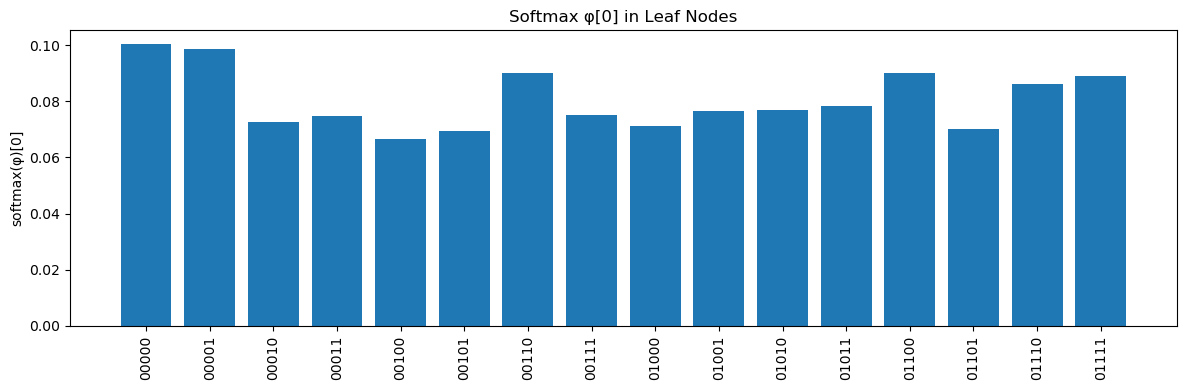

In [18]:
import matplotlib.pyplot as plt

def plot_leaf_node_phi_softmax(tree, sess, target_class=3):
    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = []
    node_ids = []

    for leaf in leaves:
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)
        phi_values.append(soft_phi[target_class])
        node_ids.append(leaf.id)

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(phi_values)), phi_values, tick_label=node_ids)
    plt.xticks(rotation=90)
    plt.ylabel(f"softmax(φ)[{target_class}]")
    plt.title(f"Softmax φ[{target_class}] in Leaf Nodes")
    plt.tight_layout()
    plt.show()


plot_leaf_node_phi_softmax(tree=fashion_tree, sess=sess, target_class=0)
